# Supplementary Figure S8: in-degree participation ratio and within-module in-degree z-score

It reads its input from the data folder (`path2data`). The figures are saved in the `figures` folder.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
from collections import defaultdict
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)

In [2]:
# the country pairs with at least 2 cited articles are kept

country_auc_df = pd.read_csv(os.path.join(path2data, 'oa_countrycites_nosameorg_auc.csv.gz'))

country_auc_df['Zscore'] = (country_auc_df['AUC'] - 0.5)/np.sqrt(country_auc_df['Cov'])

    
country_auc_df = country_auc_df[country_auc_df['N']>=2].reset_index(drop=True)


# one-sided test in the direction of the observed preference: H1 is AUC > 0.5 (over-citation)
# when Z > 0, and AUC < 0.5 (under-citation) when Z < 0
country_auc_df['pvalue'] = spstats.norm.sf(np.abs(country_auc_df['Zscore'].values))

def reject_holm(pvalues):
    reject, pvalues, _, _ = holm(pvalues, alpha=0.01, method='hs', is_sorted=False, returnsorted=False)
    return reject
    
country_auc_df['Significant'] = country_auc_df.groupby('CitedYear')['pvalue'].transform(reject_holm)

net_auc = country_auc_df[country_auc_df['CitingCountry'] != country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
net_auc = net_auc[net_auc['Significant']]
self_auc = country_auc_df[country_auc_df['CitingCountry'] == country_auc_df['CitedCountry']].sort_values(by=['CitedYear', 'CitedCountry']).reset_index(drop=True)
self_auc = self_auc[self_auc['Significant']]

comm2country = {0:['AE', 'BD', 'CN', 'CY', 'DZ', 'EG', 'ID', 'IN', 'IQ', 'IR', 'JO', 'KH', 'KR', 'KW', 'MA', 'MY', 'OM', 'PK', 'QA', 'SA', 'SG', 'TH', 'TN', 'TR', 'TW', 'VN'],
1:['AR', 'BN', 'BO', 'BR', 'BW', 'BY', 'CL', 'CM', 'CO', 'CR', 'GE', 'HK', 'HR', 'LU', 'MZ', 'NC', 'PA', 'PE', 'RU', 'SJ', 'ST', 'UY', 'VE'],
2:['AT', 'BE', 'CA', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HU', 'IE', 'IL', 'IS', 'IT', 'JP', 'MX', 'NL', 'NO', 'NP', 'NZ', 'PH', 'PL', 'PT', 'RO', 'SE', 'SI', 'SK'],
3:['AU', 'CH', 'GB', 'US'],
4:['BH', 'ET', 'GH', 'KE', 'MW', 'NG', 'TZ', 'UG', 'ZA', 'ZM', 'ZW']}

country2comm = {c:ci for ci,clist in comm2country.items() for c in clist}
poscountrylist = sorted(list(country2comm.keys()))

connected_countries = np.sort(np.unique(net_auc[net_auc['Zscore'] > 0][['CitingCountry', 'CitedCountry']].values.flatten()))
print(connected_countries.shape)


syear, eyear = 1990, 2017
net_auc = net_auc[net_auc['CitedYear'] >= syear]
net_auc = net_auc[net_auc['CitedYear'] <= eyear]
cumulative_net = net_auc.sort_values('CitedYear').drop_duplicates(subset=['CitingCountry', 'CitedCountry'], keep='last')

cumulative_net=cumulative_net[cumulative_net['Significant']==True]
cumulative_net['eSign'] = cumulative_net['Zscore'].map(np.sign)


# cumulative_net=cumulative_net[cumulative_net['Zscore']>0]
# cumulative_net['SourceCommunity'] = cumulative_net['CitingCountry'].map(country2comm)
# cumulative_net['TargetCommunity'] = cumulative_net['CitedCountry'].map(country2comm)
# cumulative_net['InterCommunity'] = cumulative_net['SourceCommunity'] != cumulative_net['TargetCommunity']


(215,)


In [3]:
pos_net=cumulative_net[cumulative_net['Zscore']>0]

net_df=pos_net[['CitingCountry','CitedCountry']]

In [4]:
community_df=pd.DataFrame({'community':country2comm}).reset_index(names=['country'])
community_df

,country,community
0,AE,0
1,BD,0
2,CN,0
3,CY,0
4,DZ,0
...,...,...
88,TZ,4
89,UG,4
90,ZA,4
91,ZM,4


In [5]:
import networkx as nx
import pandas as pd
import numpy as np
from collections import defaultdict

def directed_community_roles_full(G, community_df):
    """
    Compute within-module z-scores (in/out) and participation coefficients (in/out) for a directed network.

    Args:
        G: nx.DiGraph
        community_df: pd.DataFrame with ['country', 'community']

    Returns:
        pd.DataFrame with ['country', 'community', 'z_in', 'z_out', 'P_in', 'P_out']
    """

    community_map = dict(zip(community_df['country'], community_df['community']))
    nodes_by_community = defaultdict(set)
    for node, comm in community_map.items():
        nodes_by_community[comm].add(node)

    z_in_scores = {}
    z_out_scores = {}
    p_in_scores = {}
    p_out_scores = {}

    # Z-IN and Z-OUT
    for comm, members in nodes_by_community.items():
        # In-degree from within the same community
        in_degrees = {
            node: sum(1 for nbr in G.predecessors(node) if nbr in members)
            for node in members
        }
        in_vals = np.array(list(in_degrees.values()))
        in_mean = in_vals.mean()
        in_std = in_vals.std(ddof=1) if len(in_vals) > 1 else 1

        # Out-degree to within the same community
        out_degrees = {
            node: sum(1 for nbr in G.successors(node) if nbr in members)
            for node in members
        }
        out_vals = np.array(list(out_degrees.values()))
        out_mean = out_vals.mean()
        out_std = out_vals.std(ddof=1) if len(out_vals) > 1 else 1

        for node in members:
            z_in_scores[node] = (in_degrees[node] - in_mean) / in_std if in_std != 0 else 0
            z_out_scores[node] = (out_degrees[node] - out_mean) / out_std if out_std != 0 else 0

    # P-IN and P-OUT
    for node in G.nodes():
        # Participation coefficient based on in-links
        k_in_total = G.in_degree(node)
        in_counts = defaultdict(int)
        for nbr in G.predecessors(node):
            comm = community_map.get(nbr)
            if comm is not None:
                in_counts[comm] += 1
        if k_in_total == 0:
            p_in = 0
        else:
            p_in = 1 - sum((count / k_in_total) ** 2 for count in in_counts.values())
        p_in_scores[node] = p_in

        # Participation coefficient based on out-links
        k_out_total = G.out_degree(node)
        out_counts = defaultdict(int)
        for nbr in G.successors(node):
            comm = community_map.get(nbr)
            if comm is not None:
                out_counts[comm] += 1
        if k_out_total == 0:
            p_out = 0
        else:
            p_out = 1 - sum((count / k_out_total) ** 2 for count in out_counts.values())
        p_out_scores[node] = p_out

    # Assemble result
    results = []
    for node in G.nodes():
        if node in community_map:
            results.append({
                'country': node,
                'community': community_map[node],
                'z_in': z_in_scores.get(node, 0),
                'z_out': z_out_scores.get(node, 0),
                'P_in': p_in_scores.get(node, 0),
                'P_out': p_out_scores.get(node, 0)
            })

    return pd.DataFrame(results)


In [6]:
G = nx.from_pandas_edgelist(net_df, 'CitingCountry','CitedCountry',create_using=nx.DiGraph())

role_df = directed_community_roles_full(G, community_df)

pcountries=role_df.groupby('community', group_keys=False).apply(lambda x: x.nlargest(3, 'P_in'))
pcountries=pcountries[pcountries['P_in']!=0]['country']

zcountries=role_df.groupby('community', group_keys=False).apply(lambda x: x.nlargest(3, 'z_in'))['country']

/var/folders/pw/3c9bpx2x49j17_0h64t91zgr0000gr/T/ipykernel_78481/906915623.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pcountries=role_df.groupby('community', group_keys=False).apply(lambda x: x.nlargest(3, 'P_in'))
/var/folders/pw/3c9bpx2x49j17_0h64t91zgr0000gr/T/ipykernel_78481/906915623.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  zcountries=role_df.groupby('community', group_keys=False).a

In [7]:
colours=['#8D95A0','#2171b5','#DA6437','#DEA5A1','#2C3E6C','#6D95B6','#DEA5A1','#E48267', '#BF3530','#9CAFB7','#EAD2AC','#E6B89C']

community_colors=['#C75C56','#F09937','#7DB6AB','#3F799C','#FBE14B']

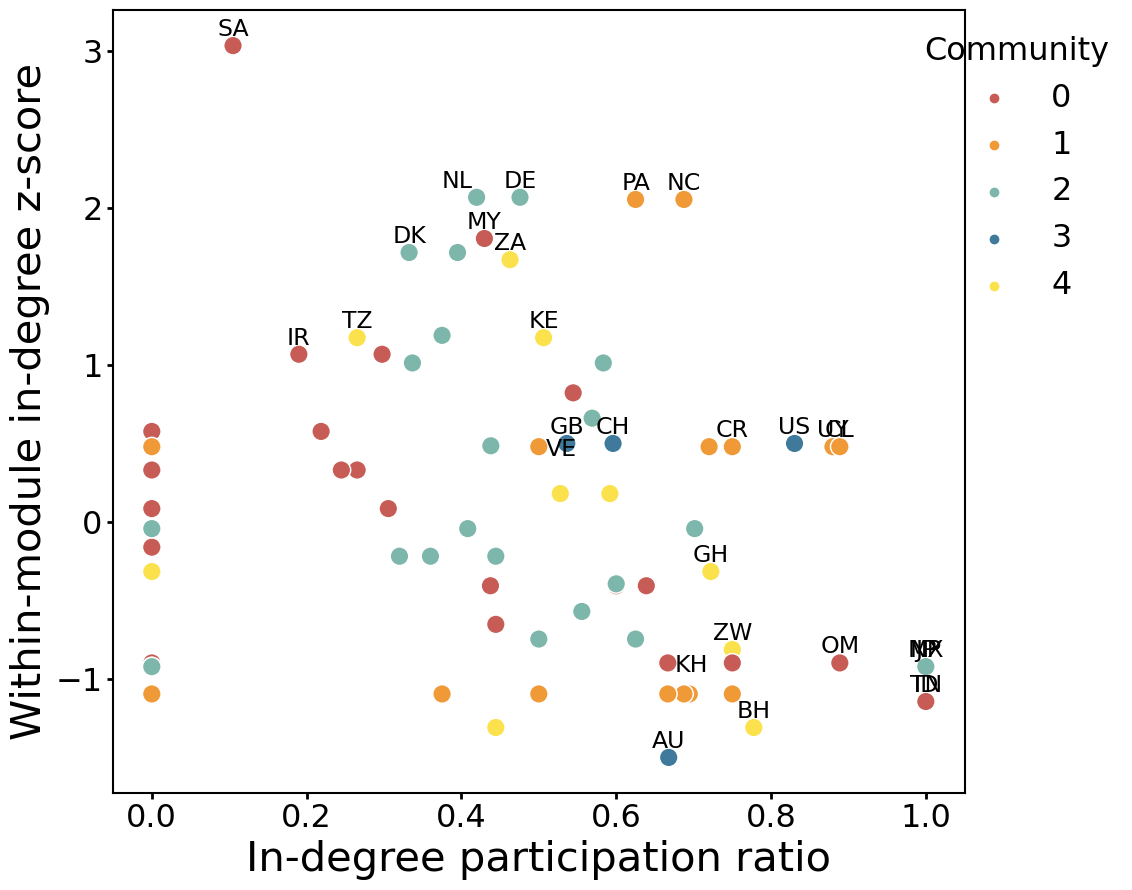

In [8]:
fig, ax = plt.subplots(figsize=(11.5, 9))

ax=sns.scatterplot(data=role_df, x='P_in', y='z_in', color=colours[1], s=180, hue='community', palette=community_colors)


ax.legend(frameon=False,  title='Community',fontsize=23, title_fontsize=23, bbox_to_anchor=(1.2, 1), borderaxespad=0.4 )

plt.tick_params(labelsize=23, direction='out', length=4, width=2) 

plt.xlabel('In-degree participation ratio', fontsize=30)
plt.ylabel('Within-module in-degree z-score', fontsize=30)


countries=set(list(pcountries)+list(zcountries))


for i, (x, y , z) in role_df[['P_in','z_in','country']].iterrows():
    if z in ['NL',]:
         plt.text(x-0.005, y+0.03, z, fontsize=17, ha='right', va='bottom', color='black')
    elif z in ['VE','KH']:
         plt.text(x+0.009, y-0.09, z, fontsize=17, ha='left', va='bottom', color='black')
    # # elif z in ['TZ']:
    #     plt.text(x+0.005, y+0.03, z, fontsize=17, ha='left', va='bottom', color='black')
   
    elif z in countries:
        plt.text(x, y+0.03, z, fontsize=17, ha='center', va='bottom', color='black')

for spine in ax.spines.values():
    spine.set_linewidth(1.5) 
plt.tight_layout()


file_name=os.path.join(path2figures, 'FigSI_BridgesHubs.pdf')
plt.savefig(file_name)

## Source Data for Supplementary Fig. S8

The values plotted, written to `Source Data/SourceData_FigS8.xlsx`.

In [9]:
from sourcedatautils import write_source_data

write_source_data('SourceData_FigS8.xlsx', 'Supplementary Figure 8: In-degree participation ratio and within-module in-degree z-score.',
                  'In-degree participation ratio (P_in) and within-module in-degree z-score (z_in) of each country, with its community as plotted.',
                  [('S8', 'Community role of each country.', role_df)])

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS8.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
